# Part 5: Expanding Walk-Forward Validation, Prior-Odds Calibration, Operating Points & Held-Out Test Evaluation
Compares supervisory baselines against regularized Logistic Regression, HistGradientBoosting, and PySpark MLlib, presents fixed-budget supervisory capacity operating points (Top 1%, 2%, 5% per quarter), cost-minimizing threshold $\theta^*$, empirical leakage parameter shift, and a live operational 2026Q2 watchlist.

In [1]:
import json
from pathlib import Path
import polars as pl

print('=== Walk-Forward Cross-Validation Comparison (DEV 1984-2007) ===')
print(pl.read_csv('../outputs/tables/cv_model_comparison.csv'))
print('\n=== Per-Fold Expanding Walk-Forward Breakdown (DEV 5 Blocks) ===')
res = json.loads(Path('../outputs/tables/test_results.json').read_text(encoding='utf-8'))
for m_name in ['Texas ratio rule', 'Logistic, 3 variables', 'Logistic, 26 CAMELS', 'HistGradientBoosting, 26 CAMELS']:
    folds = res['cross_validation_models'][m_name]['folds']
    print(f'\n-- {m_name} --')
    print(pl.DataFrame(folds).select(['val_years', 'rows', 'positive_rows', 'failing_banks', 'pr_auc', 'roc_auc', 'brier_score']))
print('\n=== DEV Label Sensitivity (FAILURE+ASSISTANCE vs FAILURE-only) ===')
print(pl.read_csv('../outputs/tables/dev_label_sensitivity.csv'))

=== Walk-Forward Cross-Validation Comparison (DEV 1984-2007) ===
shape: (4, 6)
┌──────────────────────────┬────────┬─────────┬─────────────────┬─────────────────┬─────────────┐
│ model                    ┆ pr_auc ┆ roc_auc ┆ recall_top_1pct ┆ recall_top_5pct ┆ brier_score │
│ ---                      ┆ ---    ┆ ---     ┆ ---             ┆ ---             ┆ ---         │
│ str                      ┆ f64    ┆ f64     ┆ f64             ┆ f64             ┆ f64         │
╞══════════════════════════╪════════╪═════════╪═════════════════╪═════════════════╪═════════════╡
│ Texas ratio rule         ┆ 0.2642 ┆ 0.9734  ┆ 0.6665          ┆ 0.929           ┆ 0.00724     │
│ Logistic, 3 variables    ┆ 0.4015 ┆ 0.9786  ┆ 0.7277          ┆ 0.9566          ┆ 0.00368     │
│ Logistic, 26 CAMELS      ┆ 0.3601 ┆ 0.9784  ┆ 0.7291          ┆ 0.9352          ┆ 0.00393     │
│ HistGradientBoosting, 26 ┆ 0.4624 ┆ 0.9851  ┆ 0.7753          ┆ 0.9504          ┆ 0.00337     │
│ CAMEL…                   ┆        ┆  

In [2]:
import sys
import numpy as np
from IPython.display import Image, display
sys.path.insert(0, str(Path.cwd().parent))
from src.bfews.modeling import make_model

cost_cfg = res['cost_threshold_tuning']
t_eval = res['held_out_test_evaluation']
print('=== DEV Cost-Optimal Threshold & Failing Bank Counts ===')
print({
    'theta_star': cost_cfg['theta'],
    'theta_at_grid_edge': cost_cfg['theta_at_grid_edge'],
    'dev_failing_banks_in_oof_blocks': cost_cfg['dev_failing_banks_in_oof_blocks'],
    'dev_oof_banks_caught_at_theta': cost_cfg['dev_oof_banks_caught_at_theta'],
    'dev_failing_banks_all_1984_2007': cost_cfg['dev_failing_banks_all'],
})
print('\n=== Held-Out Test Overall Metrics (2009Q1-2025Q2) ===')
print({k: t_eval[k] for k in ['pr_auc', 'roc_auc', 'recall_top_1pct', 'recall_top_5pct', 'brier_score', 'rows', 'positive_rows', 'failing_banks_total']})
print('\n=== Held-Out Test Capacity Operating Points ===')
print(pl.DataFrame(t_eval['capacity_points']))
print('\n=== Held-Out Test at Cost-Optimal Threshold ===')
print(t_eval['at_threshold'])
print('\n=== Top 10 Strictly-DEV Feature Importance (HGB Permutation + Logit Coef) ===')
print(pl.read_csv('../outputs/tables/feature_importance.csv').head(10))
print('\n=== Post-hoc Historical Canary Case Studies (Held-Out TEST Failures) ===')
print(pl.read_csv('../outputs/tables/canary_case_studies.csv'))
print('\n=== Operational 2026Q2 Top-10 Watchlist (Frozen DEV Model, Unlabelled Tail) ===')
print(pl.read_csv('../outputs/tables/watchlist_2026q2.csv').head(10))
# Live check: Elkan (2001) PriorOddsCalibrator preserves rank order while restoring rare-event prior scale
rng = np.random.default_rng(42)
X_s = rng.normal(size=(400, 4)).astype(np.float32); y_s = (rng.random(400) < 0.02).astype(int)
pipe_s = make_model('logit').fit(X_s, y_s)
p_cal = pipe_s.predict_proba(X_s)[:, 1]
print(f'\nPriorOddsCalibrator check (seed=42): train prior={y_s.mean():.4f}, mean calibrated p={p_cal.mean():.4f}')

=== DEV Cost-Optimal Threshold & Failing Bank Counts ===
{'theta_star': 0.0039, 'theta_at_grid_edge': False, 'dev_failing_banks_in_oof_blocks': 1522, 'dev_oof_banks_caught_at_theta': 1434, 'dev_failing_banks_all_1984_2007': 2661}

=== Held-Out Test Overall Metrics (2009Q1-2025Q2) ===
{'pr_auc': 0.5478, 'roc_auc': 0.9854, 'recall_top_1pct': 0.8353, 'recall_top_5pct': 0.956, 'brier_score': 0.00238, 'rows': 400332, 'positive_rows': 1409, 'failing_banks_total': 485}

=== Held-Out Test Capacity Operating Points ===
shape: (3, 12)
┌─────┬────────────┬────────────┬────────────┬───┬────────────┬────────────┬───────────┬───────────┐
│ pct ┆ failing_ba ┆ failing_ba ┆ bank_recal ┆ … ┆ false_alar ┆ alerts_per ┆ flagged_s ┆ positive_ │
│ --- ┆ nks        ┆ nks_caught ┆ l          ┆   ┆ m_episodes ┆ _quarter_m ┆ hare_of_r ┆ rows_flag │
│ i64 ┆ ---        ┆ ---        ┆ ---        ┆   ┆ ---        ┆ edian      ┆ ows_pct   ┆ ged       │
│     ┆ i64        ┆ i64        ┆ f64        ┆   ┆ i64        ┆ -

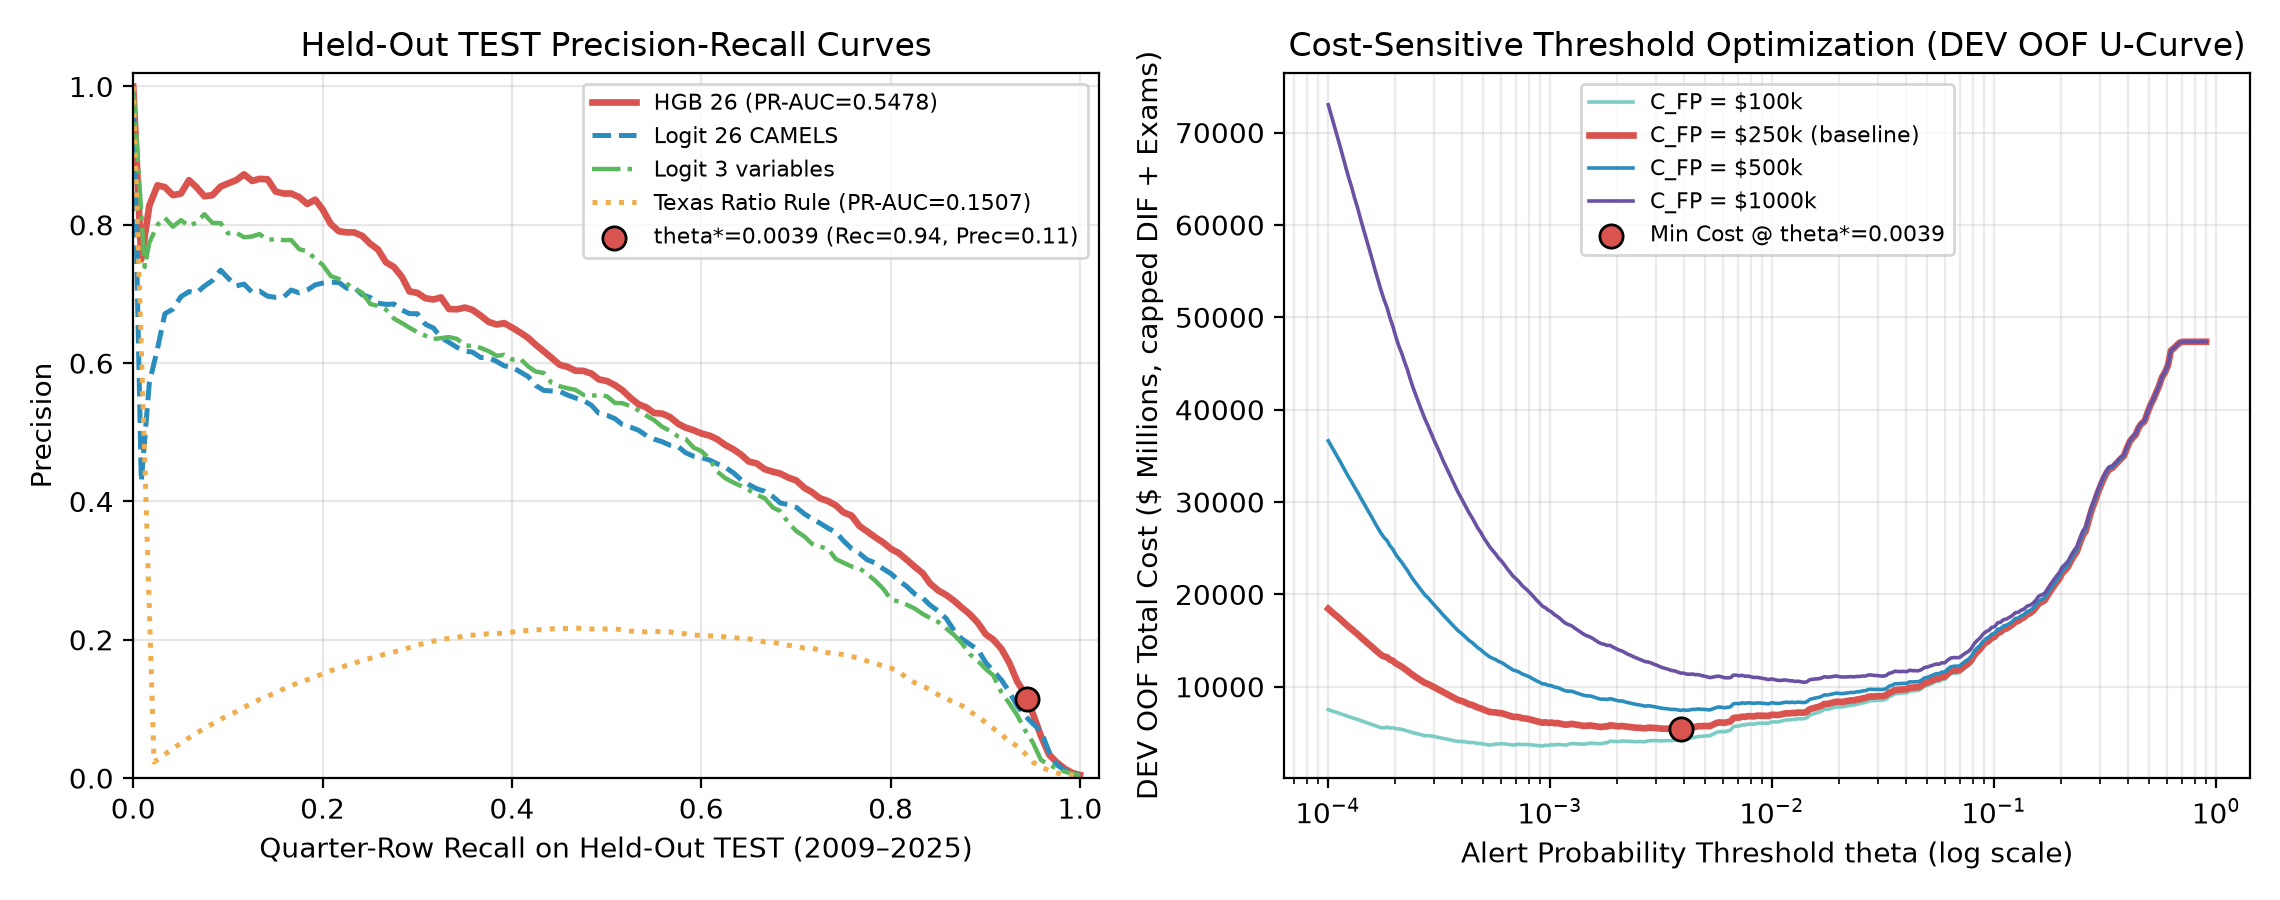

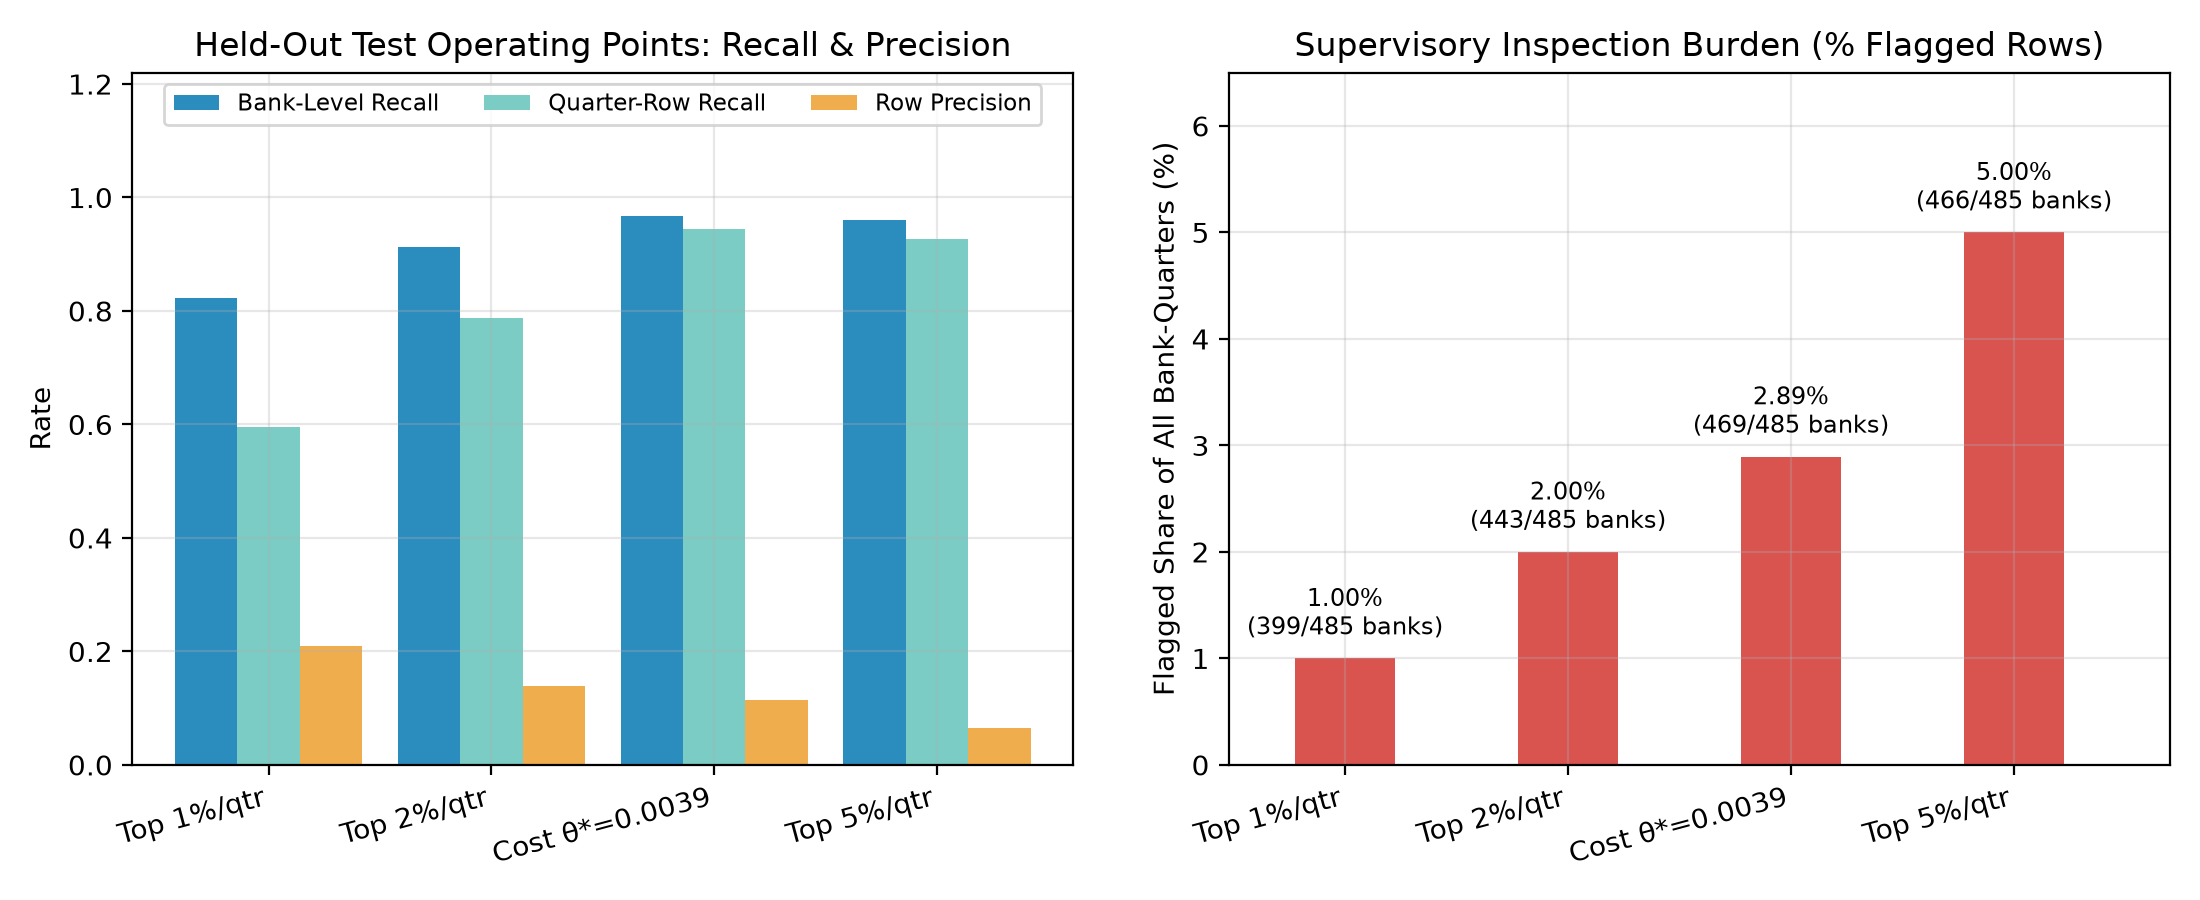

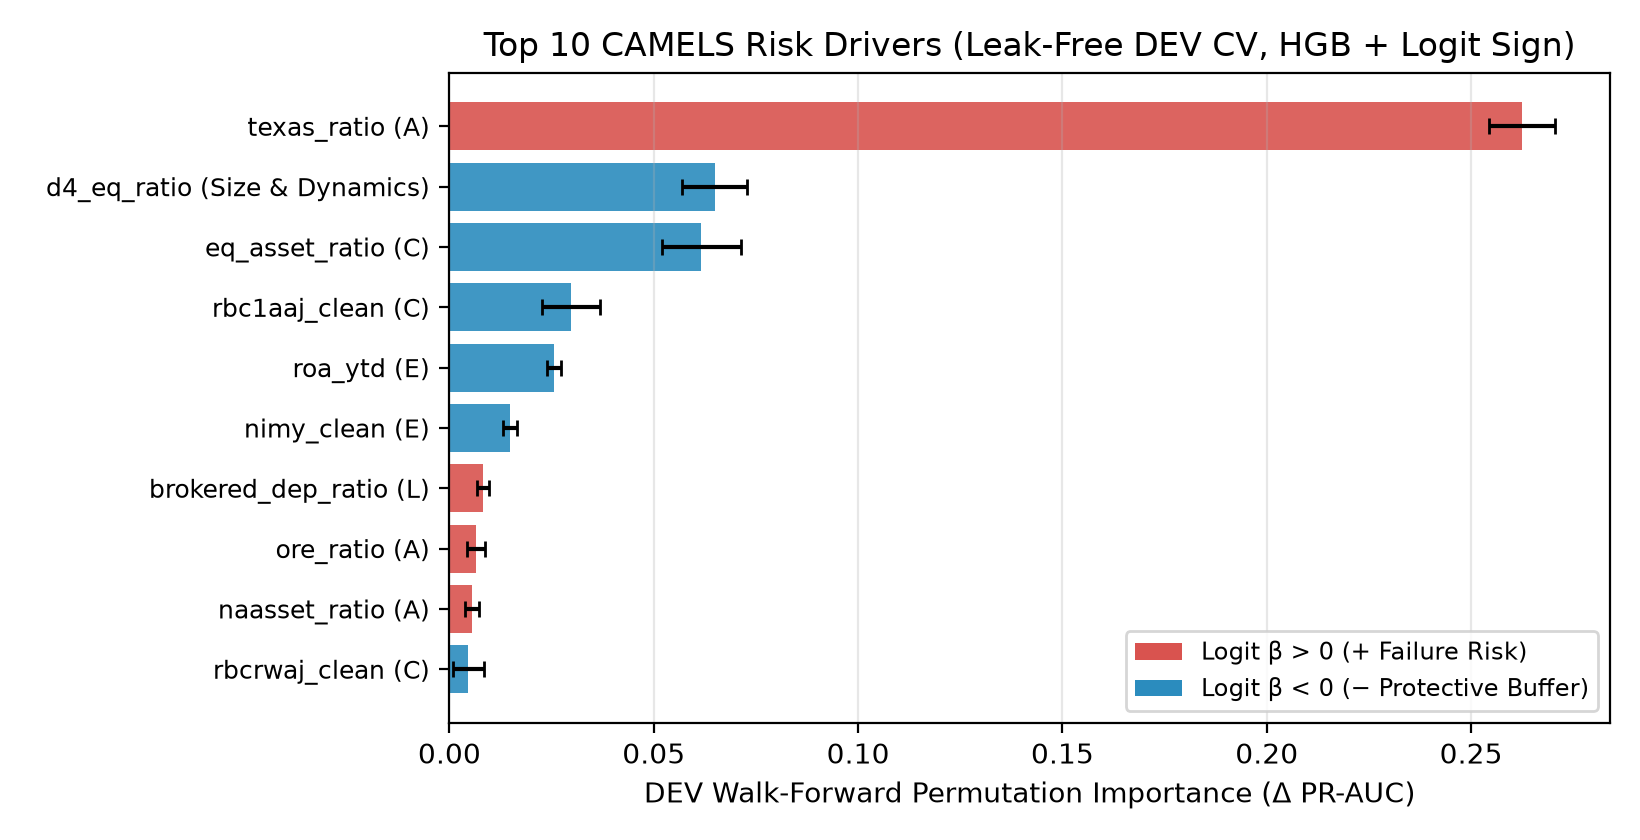

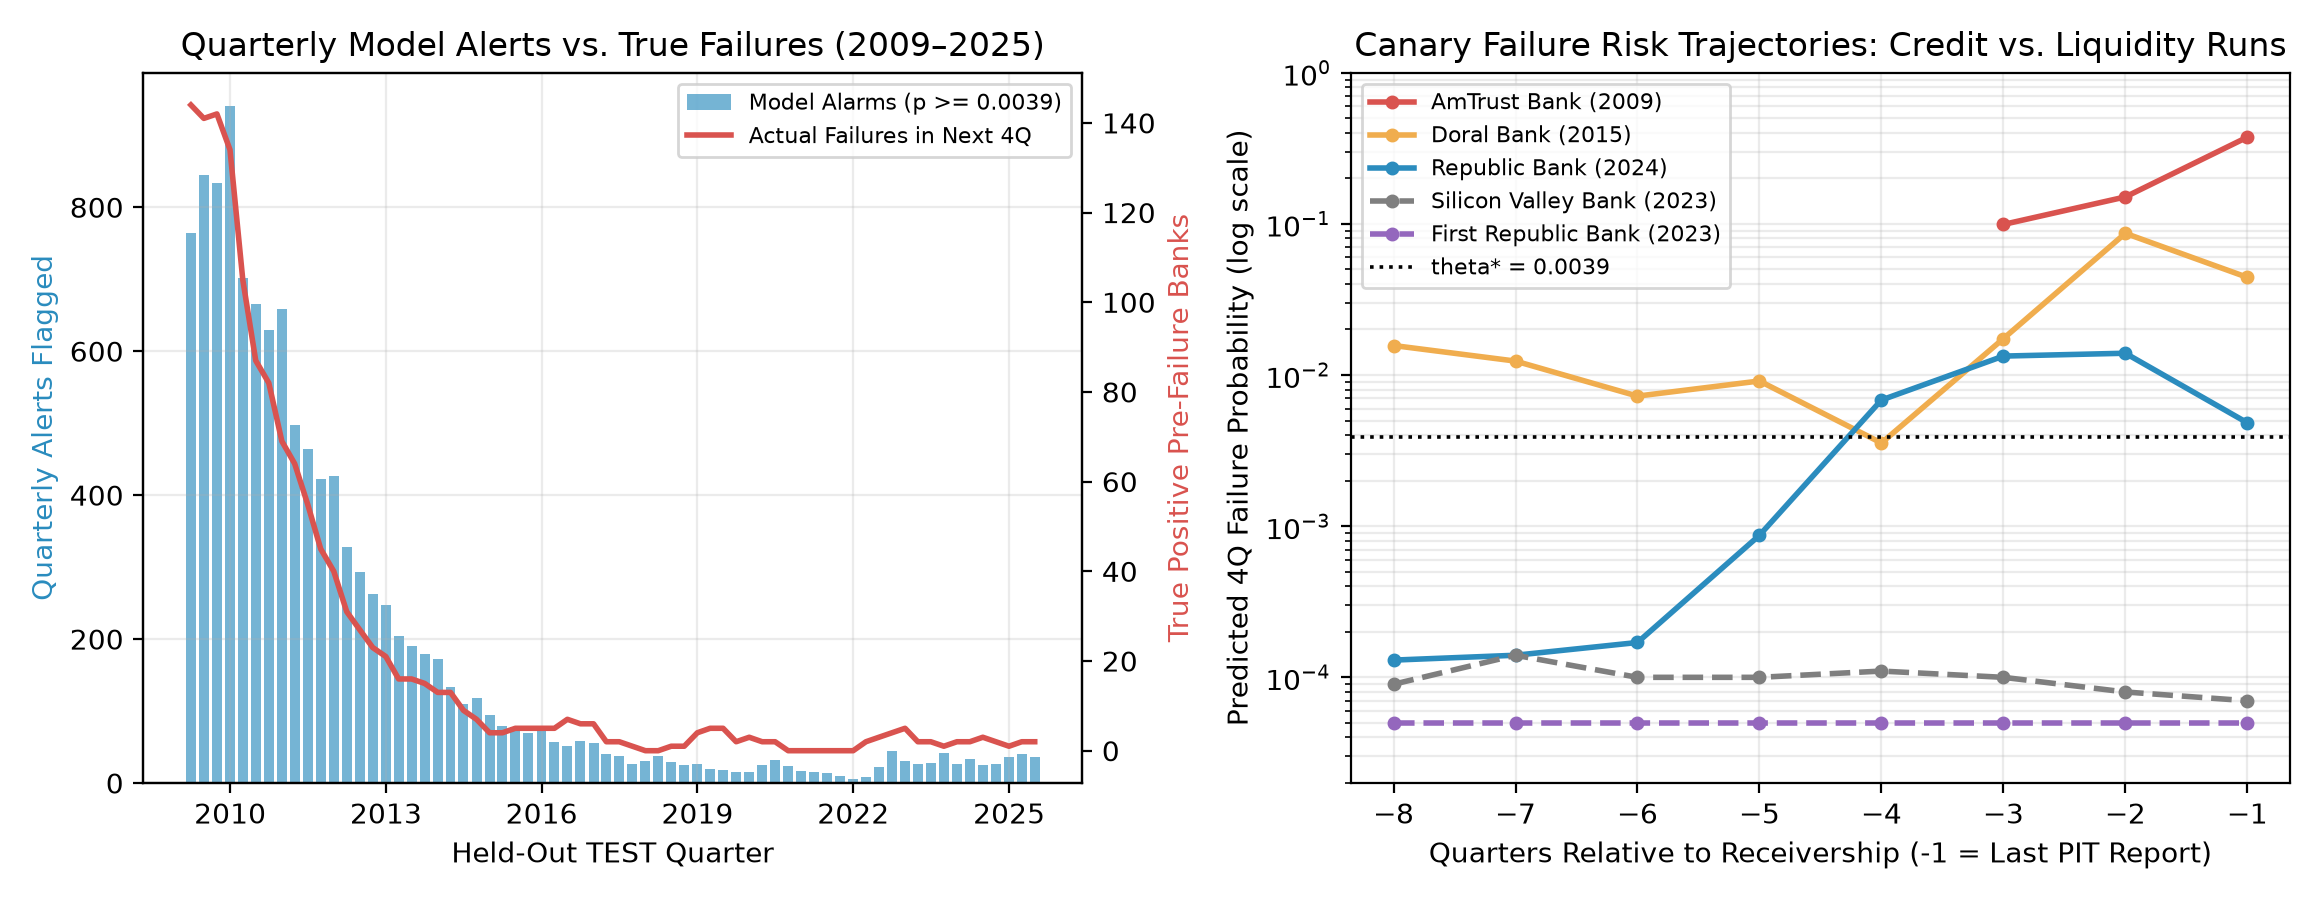

In [3]:
for fig_name in ('pr_and_cost_curves.png', 'operating_points.png', 'feature_importance.png', 'alarms_and_canary_trajectories.png'):
    display(Image(filename=f'../outputs/figures/{fig_name}'))